In [ ]:
# Article title: Identification of Thermal Class-Specific Genomic and Proteomic Compositional Signatures in Bacteria Using a Weighted Ensemble Feature Ranking Framework, 
# Author Names: Biraj Khound1, Deb K Boruah1, Pranjal Phukan1, Kalyan Sarma1, Prince Das1, Robita Doley2, Alicia Passah1;
# Affiliation: 
# 1 Department of Diagnostic and Interventional Radiology, All India Institute of Medical Sciences, Changsari, Guwahati, 781101, Assam, India.
# 2 Department of Molecular Biology and Biotechnology, Tezpur University, Napaam, Tezpur, 784028, Assam, India.
# E-mail address of the corresponding author: prsbirajaiimsguwahati@gmail.com

In [ ]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt # for data visualization
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
# import RFC classifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
# Scaller
from sklearn.preprocessing import MinMaxScaler
# compute ROC AUC
from sklearn.metrics import roc_auc_score, roc_curve, auc
pd.set_option('display.max_colwidth', None)  # None means no limit
# feature selectors
%matplotlib inline

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
dub = "/content/drive/MyDrive/paper-1/Dataset/DUB.csv"
cub = "/content/drive/MyDrive/paper-1/Dataset/CUB.csv"
cpub = "/content/drive/MyDrive/paper-1/Dataset/CPUB.csv"
aaub = "/content/drive/MyDrive/paper-1/Dataset/AAUB.csv"
aapub = "/content/drive/MyDrive/paper-1/Dataset/AAPUB.csv"
df = pd.read_csv(dub, encoding="ISO-8859-1", na_filter=False)

In [ ]:
# codon usage Bias
x_psyc = df.loc[0:17,].drop(['label-1', 'label-2'], axis=1)
x_meso = df.loc[18:52,].drop(['label-1', 'label-2'], axis=1)
x_ther = df.loc[53:84,].drop(['label-1', 'label-2'], axis=1)
# psychro vs meso and psy vs thermo
y_psyc = df.loc[0:17, ['label-1']]
y_meso = df.loc[18:52, ['label-1']]
y_ther = df.loc[53:84, ['label-1']]
# psy vs meso
y_psyc2 = df.loc[0:17, ['label-2']]
y_meso2 = df.loc[18:52, ['label-2']]
# combine data and label
x_ps_vs_me = pd.concat([x_psyc, x_meso], ignore_index=True)
y_ps_vs_me = pd.concat([y_psyc2, y_meso2], ignore_index=True)
#-------
x_me_vs_th = pd.concat([x_meso, x_ther], ignore_index=True)
y_me_vs_th = pd.concat([y_meso, y_ther], ignore_index=True)
#-------
x_th_vs_ps = pd.concat([x_psyc, x_ther], ignore_index=True)
y_th_vs_ps = pd.concat([y_psyc, y_ther], ignore_index=True)


In [ ]:
feature_importance_tittle = 'Differentially used dinucleotides among Mesophilic and Thermophilic Bacteria'

y = y_me_vs_th.values.ravel()
x = x_me_vs_th
# Bootstrap Sampling 80% unique samples
unique_frac = 0.632
n_splits = 5
# Data Normalization
# Initialize scaler
min_max_scaler = MinMaxScaler()
# Fit and transform data
x_scaled = min_max_scaler.fit_transform(x)
# Convert back to DataFrame for readability
x_scaled = pd.DataFrame(x_scaled, columns=x.columns)

In [ ]:
# Define model
classifiers = [ RandomForestClassifier(),SVC(probability=True), GaussianNB(), AdaBoostClassifier(),LogisticRegression(), KNeighborsClassifier(), XGBClassifier()]

# Define 5-fold Stratified Cross-Validation
skf = StratifiedKFold(n_splits=n_splits, shuffle=True,random_state=42)

In [ ]:
from sklearn.feature_selection import SelectKBest, chi2
from scipy.stats import kendalltau

N = len(x_scaled)
n_unique = int(unique_frac * N)
rng = np.random.default_rng(42)

#Select unique samples (without replacement)
unique_idx = rng.choice(N, size=n_unique, replace=False)

#Sample WITH replacement to reach original size
final_idx = rng.choice(unique_idx, size=N, replace=True)

X = x_scaled.iloc[final_idx] # Corrected: Use .iloc to select rows by integer position
Y = y[final_idx]

feature_names = X.columns
n_features = len(feature_names)

rankings = []          # full ranking per fold
selected_features = [] # top-k features per fold
chi2_scores = []
for train_idx, test_idx in skf.split(X, Y):
    X_train = X.iloc[train_idx]
    y_train = Y[train_idx]

    selector = SelectKBest(score_func=chi2, k='all')
    selector.fit(X_train, y_train)

    scores = selector.scores_
    chi2_scores.append(pd.Series(scores, index=feature_names))
    # Rank features (1 = best)
    rank = pd.Series(scores, index=feature_names)\
              .rank(ascending=False, method='average')

    rankings.append(rank)

kendall_taus = []

for i in range(n_splits):
    for j in range(i + 1, n_splits):
        tau, _ = kendalltau(rankings[i], rankings[j])
        kendall_taus.append(tau)

mean_kendall_tau = np.mean(kendall_taus)

rank_df = pd.concat(rankings, axis=1)
rank_df.columns = [f'Fold_{i+1}' for i in range(n_splits)]

rank_variance = rank_df.var(axis=1)
average_rank_variance = rank_variance.mean()

print(f"Mean Kendall's Tau: {mean_kendall_tau:.4f}")
print(f"Average Rank Variance: {average_rank_variance:.4f}")

normalize_kt = (mean_kendall_tau + 1)/2
normalize_arv = 1/(1+average_rank_variance)
w_chi2 = np.float64((2*normalize_kt*normalize_arv)/(normalize_arv+normalize_kt))
print(f"Normalize AKT: {normalize_kt}")
print(f"Normalize ARV: {normalize_arv}")
print(f"Custom Weight: {w_chi2}")
chi2_score_df = pd.concat(chi2_scores, axis =1)
chi2_score_df['chi2_score'] = chi2_score_df.mean(axis=1)
chi2_score_df = chi2_score_df.sort_index(ascending=False)

Mean Kendall's Tau: 0.8529
Average Rank Variance: 4.1297
Normalize AKT: 0.9264264264264265
Normalize ARV: 0.19494204425711273
Custom Weight: 0.3221054740575921


In [ ]:
chi2_score_df

,0,1,2,3,4,chi2_score
TpTpos2,2.209449,1.523786,2.417398,2.156490,2.013400,2.064105
TpTpos1,1.014249,0.675338,1.376499,0.481113,0.978067,0.905053
TpTbridge,3.507447,2.492530,4.005281,2.731311,3.329899,3.213294
TpGpos2,1.531405,1.342511,1.787841,1.578696,1.555200,1.559131
TpGbridge,1.002540,0.604993,1.101986,0.811171,0.922759,0.888690
TpCpos2,1.676346,0.908366,2.156086,1.205437,1.379106,1.465068
TpCpos1,0.508564,0.400208,0.336929,0.279229,0.446519,0.394290
TpCbridge,0.351988,0.126835,0.407254,0.352792,0.228930,0.293560
TpApos2,1.315252,1.205158,1.848487,1.206180,1.418837,1.398783
TpAbridge,1.074243,0.846996,1.574546,0.887282,1.021102,1.080834


In [ ]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from scipy.stats import kendalltau

N = len(x_scaled)
n_unique = int(unique_frac * N)
rng = np.random.default_rng(43)

#Select unique samples (without replacement)
unique_idx = rng.choice(N, size=n_unique, replace=False)

#Sample WITH replacement to reach original size
final_idx = rng.choice(unique_idx, size=N, replace=True)

X = x_scaled.iloc[final_idx] # Corrected: Use .iloc to select rows by integer position
Y = y[final_idx]

feature_names = X.columns
n_features = len(feature_names)

rankings = []          # full ranking per fold
selected_features = [] # top-k features per fold
mi_scores = []
for train_idx, test_idx in skf.split(X, Y):
    X_train = X.iloc[train_idx]
    y_train = Y[train_idx]

    selector = SelectKBest(score_func=mutual_info_classif, k='all')
    selector.fit(X_train, y_train)

    scores = selector.scores_
    mi_scores.append(pd.Series(scores, index=feature_names))
    # Rank features (1 = best)
    rank = pd.Series(scores, index=feature_names)\
              .rank(ascending=False, method='average')

    rankings.append(rank)

kendall_taus = []

for i in range(n_splits):
    for j in range(i + 1, n_splits):
        tau, _ = kendalltau(rankings[i], rankings[j])
        kendall_taus.append(tau)

mean_kendall_tau = np.mean(kendall_taus)

rank_df = pd.concat(rankings, axis=1)
rank_df.columns = [f'Fold_{i+1}' for i in range(n_splits)]

rank_variance = rank_df.var(axis=1)
average_rank_variance = rank_variance.mean()

print(f"Mean Kendall's Tau: {mean_kendall_tau:.4f}")
print(f"Average Rank Variance: {average_rank_variance:.4f}")


normalize_kt = (mean_kendall_tau + 1)/2
normalize_arv = 1/(1+average_rank_variance)
w_mi = np.float64((2*normalize_kt*normalize_arv)/(normalize_arv+normalize_kt))
print(f"Normalize AKT: {normalize_kt}")
print(f"Normalize ARV: {normalize_arv}")
print(f"Custom Weight: {w_mi}")
mi_scores_df = pd.concat(mi_scores, axis =1)
mi_scores_df['mi_scores'] = mi_scores_df.mean(axis=1)
mi_scores_df = mi_scores_df.sort_index(ascending=False)

Mean Kendall's Tau: 0.4982
Average Rank Variance: 38.8649
Normalize AKT: 0.7490963855421686
Normalize ARV: 0.025084745762711864
Custom Weight: 0.04854391723915999


In [ ]:
mi_scores_df

,0,1,2,3,4,mi_scores
TpTpos2,0.261291,0.349214,0.214365,0.297785,0.274223,0.279376
TpTpos1,0.212420,0.221499,0.329550,0.365412,0.165807,0.258938
TpTbridge,0.252571,0.301710,0.241155,0.313218,0.285887,0.278908
TpGpos2,0.107242,0.125363,0.259009,0.135178,0.109397,0.147238
TpGbridge,0.150424,0.209985,0.158796,0.244982,0.116577,0.176153
TpCpos2,0.167580,0.273840,0.263036,0.246643,0.137281,0.217676
TpCpos1,0.327776,0.311436,0.378262,0.392805,0.310523,0.344160
TpCbridge,0.291972,0.303663,0.298801,0.307664,0.262323,0.292885
TpApos2,0.189955,0.259583,0.337398,0.314953,0.152121,0.250802
TpAbridge,0.206016,0.265111,0.338216,0.272499,0.186205,0.253609


In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
from scipy.stats import kendalltau


N = len(x_scaled)
n_unique = int(unique_frac * N)
rng = np.random.default_rng(44)

#Select unique samples (without replacement)
unique_idx = rng.choice(N, size=n_unique, replace=False)

#Sample WITH replacement to reach original size
final_idx = rng.choice(unique_idx, size=N, replace=True)

X = x_scaled.iloc[final_idx] # Corrected: Use .iloc to select rows by integer position
Y = y[final_idx]

feature_names = X.columns
n_features = len(feature_names)

rankings = []          # full ranking per fold
selected_features = [] # top-k features per fold
fs_scores = []
for train_idx, test_idx in skf.split(X, Y):
    X_train = X.iloc[train_idx]
    y_train = Y[train_idx]

    selector = SelectKBest(score_func=f_classif, k='all')
    selector.fit(X_train, y_train)

    scores = selector.scores_
    fs_scores.append(pd.Series(scores, index=feature_names))
    # Rank features (1 = best)
    rank = pd.Series(scores, index=feature_names)\
              .rank(ascending=False, method='average')

    rankings.append(rank)


kendall_taus = []

for i in range(n_splits):
    for j in range(i + 1, n_splits):
        tau, _ = kendalltau(rankings[i], rankings[j])
        kendall_taus.append(tau)

mean_kendall_tau = np.mean(kendall_taus)

rank_df = pd.concat(rankings, axis=1)
rank_df.columns = [f'Fold_{i+1}' for i in range(n_splits)]

rank_variance = rank_df.var(axis=1)
average_rank_variance = rank_variance.mean()

print(f"Mean Kendall's Tau: {mean_kendall_tau:.4f}")
print(f"Average Rank Variance: {average_rank_variance:.4f}")

normalize_kt = (mean_kendall_tau + 1)/2
normalize_arv = 1/(1+average_rank_variance)
w_fs = np.float64((2*normalize_kt*normalize_arv)/(normalize_arv+normalize_kt))
print(f"Normalize AKT: {normalize_kt}")
print(f"Normalize ARV: {normalize_arv}")
print(f"Custom Weight: {w_fs}")
fs_scores_df = pd.concat(fs_scores, axis =1)
fs_scores_df['fs_scores'] = fs_scores_df.mean(axis=1)
fs_scores_df = fs_scores_df.sort_index(ascending=False)

Mean Kendall's Tau: 0.8339
Average Rank Variance: 5.6216
Normalize AKT: 0.9169311363384812
Normalize ARV: 0.1510204081632653
Custom Weight: 0.25932883412243174


In [ ]:
fs_scores_df

,0,1,2,3,4,fs_scores
TpTpos2,10.575720,25.390366,26.121908,17.842498,15.096003,19.005299
TpTpos1,4.533094,19.235418,16.941899,5.265787,6.329139,10.461068
TpTbridge,9.780492,26.950932,27.198844,13.521334,13.152828,18.120886
TpGpos2,2.445458,13.823521,13.458320,7.893477,6.622520,8.848659
TpGbridge,7.528098,17.101072,16.930440,8.972416,8.734407,11.853287
TpCpos2,8.263897,24.107422,24.208796,12.613847,11.491085,16.137009
TpCpos1,0.074366,0.355198,0.033819,0.514471,1.021759,0.399923
TpCbridge,1.859080,4.596041,2.878099,3.843828,3.591388,3.353687
TpApos2,9.972255,34.763251,33.496114,19.220909,18.294388,23.149384
TpAbridge,3.322532,21.300651,19.090605,9.238824,8.232374,12.236997


In [ ]:
# Relief Feature Selector
! pip install skrebate

In [ ]:
# Relief Feature Selector
from skrebate import ReliefF
feature_names = x_scaled.columns


N = len(x_scaled)
n_unique = int(unique_frac * N)
rng = np.random.default_rng(45)

#Select unique samples (without replacement)
unique_idx = rng.choice(N, size=n_unique, replace=False)

#Sample WITH replacement to reach original size
final_idx = rng.choice(unique_idx, size=N, replace=True)

X = x_scaled.iloc[final_idx] # Corrected: Use .iloc to select rows by integer position
Y = y[final_idx]

rankings = []
selected_features =[]
relief_scores = []
for train_idx, test_idx in skf.split(X, Y):
    X_train = X.iloc[train_idx]
    y_train = Y[train_idx]

    # Initialize ReliefF selector
    relief = ReliefF(n_neighbors=10)  # n_neighbors controls sensitivity to feature interactions
    # Fit ReliefF to the data
    relief.fit(X_train.values,y_train)
    # Get feature scores
    r_scores = relief.feature_importances_
    relief_scores.append(pd.Series(r_scores, index=feature_names))
    # Rank features (1 = best)
    rank = pd.Series(scores, index=feature_names)\
              .rank(ascending=False, method='average')

    rankings.append(rank)

kendall_taus = []

for i in range(n_splits):
    for j in range(i + 1, n_splits):
        tau, _ = kendalltau(rankings[i], rankings[j])
        kendall_taus.append(tau)

mean_kendall_tau = np.mean(kendall_taus)

rank_df = pd.concat(rankings, axis=1)
rank_df.columns = [f'Fold_{i+1}' for i in range(n_splits)]

rank_variance = rank_df.var(axis=1)
average_rank_variance = rank_variance.mean()

print(f"Mean Kendall's Tau: {mean_kendall_tau:.4f}")
print(f"Average Rank Variance: {average_rank_variance:.4f}")

normalize_kt = (mean_kendall_tau + 1)/2
normalize_arv = 1/(1+average_rank_variance)
w_reliefF = np.float64((2*normalize_kt*normalize_arv)/(normalize_arv+normalize_kt))
print(f"Normalize AKT: {normalize_kt}")
print(f"Normalize ARV: {normalize_arv}")
print(f"Custom Weight: {w_reliefF}")
reliefF_scores_df = pd.concat(relief_scores, axis =1)
reliefF_scores_df['reliefF_scores'] = reliefF_scores_df.mean(axis=1)
reliefF_scores_df = reliefF_scores_df.sort_index(ascending=False)

Mean Kendall's Tau: 1.0000
Average Rank Variance: 0.0000
Normalize AKT: 1.0
Normalize ARV: 1.0
Custom Weight: 1.0


In [ ]:
reliefF_scores_df

,0,1,2,3,4,reliefF_scores
TpTpos2,0.041136,0.048785,0.053336,0.040157,0.042944,0.045272
TpTpos1,0.010153,0.000277,0.010607,0.009715,0.032795,0.012709
TpTbridge,0.052835,0.052329,0.063952,0.054507,0.071497,0.059024
TpGpos2,0.032549,0.030171,0.055270,0.031328,0.041608,0.038185
TpGbridge,0.031665,0.037158,0.044929,0.033910,0.028661,0.035265
TpCpos2,0.026913,0.017304,0.028942,0.018065,0.023145,0.022874
TpCpos1,0.015800,0.019848,0.023857,0.026276,0.001925,0.017541
TpCbridge,0.008499,0.001624,0.015446,0.014617,0.016573,0.011352
TpApos2,0.012964,0.015653,0.020088,0.021062,0.029801,0.019914
TpAbridge,0.011956,0.012489,0.009276,0.022284,0.019165,0.015034


In [ ]:
w = np.array([w_chi2, w_mi, w_fs, w_reliefF])
wf = w/w.sum()
wf_df = pd.DataFrame(    [
        ["Chi_Square", wf[0]],
        ["mutual_info_classif", wf[1]],
        ["fisher_score", wf[2]],
        ["reliefF", wf[3]]
    ],
    columns=["feature selector", "weights"])

In [ ]:
wf_df

,feature selector,weights
0,Chi_Square,0.197613
1,mutual_info_classif,0.029782
2,fisher_score,0.159100
3,reliefF,0.613505


In [ ]:
mean_scores_df = pd.concat([ chi2_score_df['chi2_score'], mi_scores_df['mi_scores'], fs_scores_df['fs_scores'], reliefF_scores_df['reliefF_scores']], axis=1)
weighted_scores_df = pd.DataFrame({'weighted_feature_score': mean_scores_df[['chi2_score', 'mi_scores', 'fs_scores', 'reliefF_scores']].mul(wf).sum(axis=1) })
weighted_scores_df = weighted_scores_df.sort_index(ascending=False)
weighted_ranks = pd.DataFrame({'weighted_rank': weighted_scores_df['weighted_feature_score'].rank(ascending=False).sort_index(ascending=False)})
feature_score_df = pd.concat([ chi2_score_df['chi2_score'], mi_scores_df['mi_scores'], fs_scores_df['fs_scores'], reliefF_scores_df['reliefF_scores'], weighted_scores_df['weighted_feature_score'], weighted_ranks['weighted_rank']], axis=1)
feature_score_df = feature_score_df.sort_index(ascending=False)

In [ ]:
feature_score_df.to_csv('/content/drive/MyDrive/paper-1/Feature_ranks/'+feature_importance_tittle+'_feature_importance_scores.xlsx', index=True) # Set index=True to save feature names
wf_df.to_csv('/content/drive/MyDrive/paper-1/Feature_ranks/'+feature_importance_tittle+'_custom_weights_for_feature_selectors.xlsx', index=True)

In [ ]:
feature_score_df

,chi2_score,mi_scores,fs_scores,reliefF_scores,weighted_feature_score,weighted_rank
TpTpos2,2.064105,0.279376,19.005299,0.045272,3.467724,10.0
TpTpos1,0.905053,0.258938,10.461068,0.012709,1.858711,20.0
TpTbridge,3.213294,0.278908,18.120886,0.059024,3.562533,9.0
TpGpos2,1.559131,0.147238,8.848659,0.038185,1.743735,21.0
TpGbridge,0.888690,0.176153,11.853287,0.035265,2.088351,18.0
TpCpos2,1.465068,0.217676,16.137009,0.022874,2.877424,15.0
TpCpos1,0.394290,0.344160,0.399923,0.017541,0.162556,34.0
TpCbridge,0.293560,0.292885,3.353687,0.011352,0.607268,30.0
TpApos2,1.398783,0.250802,23.149384,0.019914,3.979162,7.0
TpAbridge,1.080834,0.253609,12.236997,0.015034,2.177265,17.0


In [ ]:
selected_features = weighted_scores_df.sort_values(by='weighted_feature_score', ascending=False)

# Initialize result_my_ens, final_result, and roc_auc_df as dictionaries
result_my_ens = {}
final_result = {}
roc_auc_df = {}

# r0 = pd.DataFrame({'zero': [0]*7})
n = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9,1]
for i in range(0,len(n),1):
  k_features_to_select = int(n[i]*len(selected_features))
  # Ensure k_features_to_select is not zero, as it would cause issues with X_my_ens selection
  if k_features_to_select == 0:
      print(f"Skipping {n[i]*100}% features as 0 features selected.")
      continue

  my_ens_features = selected_features.head(k_features_to_select).index.tolist()
  print(my_ens_features)
  X_my_ens = x_scaled[my_ens_features]
  X = X_my_ens
  Y = y
  key = f"result_my_ens_{int(n[i]*100)}"
  result_my_ens[key] = [] # Initialize the list for current key within the dictionary
  # Evaluate using cross-validation
  for c_idx in range(0,len(classifiers)):
    ac_scores = cross_val_score(classifiers[c_idx], X, Y, cv=skf, scoring='accuracy')
    accuracy = f"{np.mean(ac_scores):.4f} \u00B1 {np.std(ac_scores):.4f}"
    f1_scores = cross_val_score(classifiers[c_idx], X, Y, cv=skf, scoring='f1')
    f1_score = f"{np.mean(f1_scores):.4f} \u00B1 {np.std(f1_scores):.4f}"
    pr_scores = cross_val_score(classifiers[c_idx], X, Y, cv=skf, scoring='precision')
    precision = f"{np.mean(pr_scores):.4f} \u00B1 {np.std(pr_scores):.4f}"
    re_scores = cross_val_score(classifiers[c_idx], X, Y, cv=skf, scoring='recall')
    recall = f"{np.mean(re_scores):.4f} \u00B1 {np.std(re_scores):.4f}"
    roc_auc_scores = cross_val_score(classifiers[c_idx], X, Y, cv=skf, scoring='roc_auc')
    roc_auc = f"{np.mean(roc_auc_scores):.4f} \u00B1 {np.std(roc_auc_scores):.4f}"
    jw_scores = cross_val_score(classifiers[c_idx], X, Y, cv=skf, scoring='jaccard_weighted')
    j_weight = f"{np.mean(jw_scores):.4f} \u00B1 {np.std(jw_scores):.4f}"
    mc_scores = cross_val_score(classifiers[c_idx], X, Y, cv=skf, scoring='matthews_corrcoef')
    mc_coef = f"{np.mean(mc_scores):.4f} \u00B1 {np.std(mc_scores):.4f}"
    result_my_ens[key].append({ 'classifiers': classifiers[c_idx].__class__.__name__, 'accuracy': accuracy,  'precision': precision, 'recall' : recall,'f1 score': f1_score,
                  'roc_auc_score': roc_auc,'jaccard_weighted': j_weight,'matthews_corrcoef': mc_coef})
    print(str(n[i]*100) + " % features processed")
  result_my_ens[key] = pd.DataFrame(result_my_ens[key])

  # Set the index for 'roc auc' series to classifier names before adding to roc_auc_df
  current_roc_auc_series = result_my_ens[key]['roc_auc_score'].apply(lambda x: float(x.split(' \u00B1 ')[0]))
  # Use classifier class names for cleaner indexing
  current_roc_auc_series.index = [c for c in result_my_ens[key]['classifiers']]

  final_result[str(n[i]*100) + '% features'] = result_my_ens[key]
  roc_auc_df[int(n[i]*100)] = current_roc_auc_series

final_ens_result = final_result # final_result is already a dictionary of DataFrames
roc_auc_data = pd.DataFrame(roc_auc_df) # Convert the roc_auc_df dictionary to a DataFrame


['CpGpos1', 'ApGpos1', 'CpTpos2']
10.0 % features processed
10.0 % features processed
10.0 % features processed
10.0 % features processed
10.0 % features processed
10.0 % features processed
10.0 % features processed
['CpGpos1', 'ApGpos1', 'CpTpos2', 'ApGbridge', 'ApAbridge', 'GpApos2', 'TpApos2']
20.0 % features processed
20.0 % features processed
20.0 % features processed
20.0 % features processed
20.0 % features processed
20.0 % features processed
20.0 % features processed
['CpGpos1', 'ApGpos1', 'CpTpos2', 'ApGbridge', 'ApAbridge', 'GpApos2', 'TpApos2', 'CpGbridge', 'TpTbridge', 'TpTpos2', 'GpCpos2']
30.0 % features processed
30.0 % features processed
30.0 % features processed
30.0 % features processed
30.0 % features processed
30.0 % features processed
30.0 % features processed
['CpGpos1', 'ApGpos1', 'CpTpos2', 'ApGbridge', 'ApAbridge', 'GpApos2', 'TpApos2', 'CpGbridge', 'TpTbridge', 'TpTpos2', 'GpCpos2', 'CpCbridge', 'CpGpos2', 'GpCbridge']
40.0 % features processed
40.0 % features

In [ ]:
output_excel_path = f'/content/drive/MyDrive/paper-1/Validation_of_feature_rank/{feature_importance_tittle}_all_classification_outputs.xlsx'

with pd.ExcelWriter(output_excel_path) as writer:
    for key, df_value in final_ens_result.items():
        df_value.to_excel(writer, sheet_name=key, index=True)

print(f"All DataFrames saved to a single Excel file: {output_excel_path}")

All DataFrames saved to a single Excel file: /content/drive/MyDrive/paper-1/Validation_of_feature_rank/Differentially used dinucleotides among Mesophilic and Thermophilic Bacteria_all_classification_outputs.xlsx


In [ ]:
final_ens_result

{'10.0% features':               classifiers         accuracy        precision           recall  \
 0  RandomForestClassifier  0.7033 ± 0.1214  0.7611 ± 0.1507  0.6381 ± 0.2517   
 1                     SVC  0.7473 ± 0.0993  0.8033 ± 0.1301  0.6286 ± 0.1465   
 2              GaussianNB  0.7593 ± 0.1155  0.7489 ± 0.1262  0.7429 ± 0.1673   
 3      AdaBoostClassifier  0.6560 ± 0.0798  0.6968 ± 0.1739  0.6333 ± 0.2122   
 4      LogisticRegression  0.7593 ± 0.1155  0.7489 ± 0.1262  0.7429 ± 0.1673   
 5    KNeighborsClassifier  0.7473 ± 0.1010  0.8400 ± 0.1497  0.6000 ± 0.1408   
 6           XGBClassifier  0.6879 ± 0.1226  0.6444 ± 0.1015  0.7286 ± 0.2454   
 
           f1 score    roc_auc_score jaccard_weighted matthews_corrcoef  
 0  0.6800 ± 0.1904  0.8429 ± 0.0877  0.5874 ± 0.1575   0.4294 ± 0.2332  
 1  0.6987 ± 0.1268  0.8626 ± 0.0625  0.6017 ± 0.1267   0.5047 ± 0.2015  
 2  0.7410 ± 0.1308  0.8639 ± 0.0733  0.6235 ± 0.1358   0.5243 ± 0.2386  
 3  0.6189 ± 0.1253  0.8201 ± 0.0550

In [ ]:
roc_auc_data

,10,20,30,40,50,60,70,80,90,100
RandomForestClassifier,0.8429,0.8486,0.8935,0.9122,0.8857,0.8782,0.8963,0.8796,0.8673,0.9099
SVC,0.8626,0.8422,0.8762,0.8463,0.8612,0.8524,0.8565,0.8646,0.8551,0.8687
GaussianNB,0.8639,0.8531,0.8293,0.8252,0.8204,0.8129,0.8041,0.8034,0.7952,0.8075
AdaBoostClassifier,0.8201,0.8837,0.9255,0.8993,0.8626,0.8759,0.8561,0.9180,0.8252,0.8429
LogisticRegression,0.8510,0.8435,0.8435,0.8435,0.8476,0.8476,0.8605,0.8653,0.8510,0.8639
KNeighborsClassifier,0.7721,0.8531,0.8741,0.8371,0.8507,0.8531,0.8204,0.7905,0.7973,0.8082
XGBClassifier,0.8163,0.8245,0.9361,0.9143,0.8810,0.9010,0.9187,0.9160,0.8735,0.8714


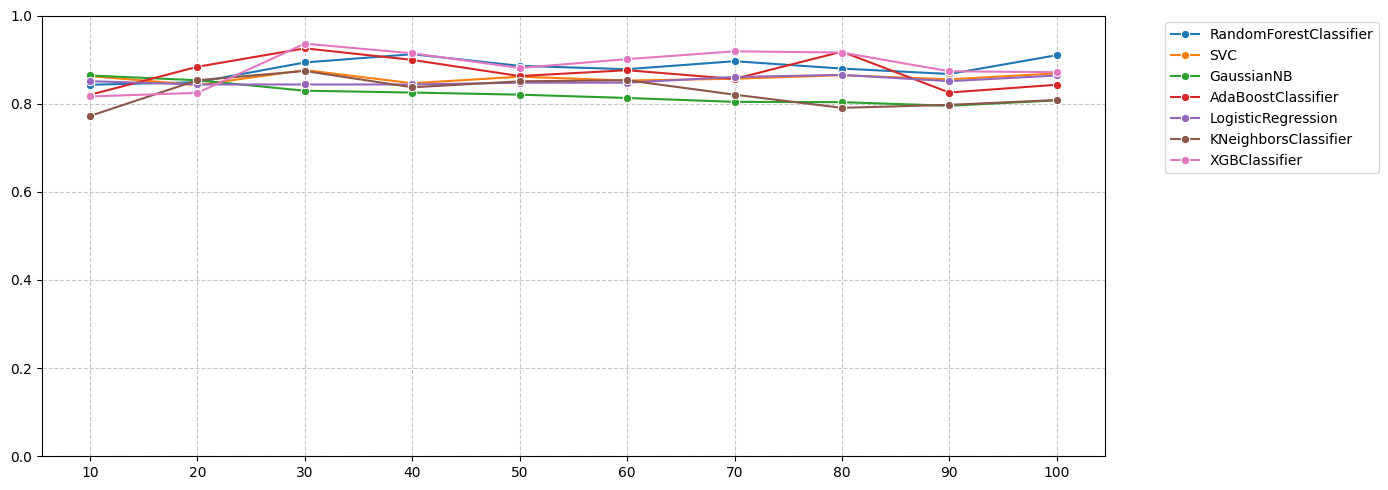

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
# Melt the DataFrame to long format for easier plotting with seaborn
plot_data_roc = roc_auc_data.reset_index().melt(id_vars='index', var_name='Percentage_features', value_name='Mean_ROC_AUC')
plot_data_roc = plot_data_roc.rename(columns={'index': 'Classifier'})

# Map classifier names to the requested abbreviations
classifier_map = {
    'RandomForestClassifier': 'Random Forest',
    'SVC': 'SVC',
    'GaussianNB': 'GaussianNB',
    'AdaBoostClassifier': 'AdaBoost',
    'LogisticRegression': 'LR',
    'KNeighborsClassifier': 'KNeighbors',
    'XGBClassifier': 'XGB'
}
plot_data_roc['Classifier'] = plot_data_roc['Classifier'].map(classifier_map)

# Convert 'Percentage_features' to string before using .str accessor
plot_data_roc['Percentage_Features_Numeric'] = plot_data_roc['Percentage_features'].astype(str).str.replace('% features', '', regex=False).astype(float)

# Replace '% data' in the 'Percentage_Data' column for display purposes
# Convert the numeric column to int and then to string for integer display on x-axis
plot_data_roc['Percentage_Features'] = plot_data_roc['Percentage_Features_Numeric'].astype(int).astype(str)

# Sort the data by numeric percentage for correct line plot order
plot_data_roc = plot_data_roc.sort_values(by='Percentage_Features_Numeric')

plt.figure(figsize=(14, 6))
sns.lineplot(data=plot_data_roc, x='Percentage_Features', y='Mean_ROC_AUC', hue='Classifier', marker='o')

# plt.title("Mean ROC AUC vs. Percentage of Selected Features for Different Classifiers ("+feature_importance_tittle+")")
plt.rcParams.update({
    'font.size': 14.5,           # Base font size
    'font.family': 'serif',    # Options: 'sans-serif', 'serif', 'monospace'
    'axes.titlesize': 14.5,      # Title font size
    'axes.labelsize': 14.5,      # X and Y label font size
    'xtick.labelsize': 14.5,     # X-axis tick font size
    'ytick.labelsize': 14.5,     # Y-axis tick font size
    'legend.fontsize': 14.5      # Slightly smaller legend font size to fit horizontally
})
plt.xlabel('Percentage of Features')
plt.ylabel('ROC AUC Score')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=0) # Rotate x-axis labels if they overlap

# Place legend at the bottom in a single row
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=7)

plt.ylim(0.6, 1.0) # Set y-axis limits from 0.6 to 1.0
plt.tight_layout()

# Save the plot to Google Drive
plt.savefig(f"/content/drive/MyDrive/paper-1/Validation_of_feature_rank/{feature_importance_tittle}_features_vs_roc_auc_plot.tiff", dpi=300, bbox_inches='tight')
plt.show()